# P22 JenaClimateForecasting: EDA
M Sanjhay Baargav (623147), Trinesh Kumar (623138).
Explore training data before model selection. See data/README.md for provenance.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

In [2]:
from scripts.get_data import main
main()
from src.data import load_hourly, TARGET
parts, observed, mean, std, audit = load_hourly()
audit

D:\XboxGames\sanjay\Sanjhay_EC417_P22_Jena_Climate\Term Project\data\raw\jena_climate_2009_2016.csv


{'raw_rows': 420551,
 'duplicate_timestamps': 327,
 'sentinel_counts': {'p (mbar)': 0,
  'T (degC)': 0,
  'Tpot (K)': 0,
  'Tdew (degC)': 0,
  'rh (%)': 0,
  'VPmax (mbar)': 0,
  'VPact (mbar)': 0,
  'VPdef (mbar)': 0,
  'sh (g/kg)': 0,
  'H2OC (mmol/mol)': 0,
  'rho (g/m**3)': 0,
  'wv (m/s)': 18,
  'max. wv (m/s)': 20,
  'wd (deg)': 0},
 'missing_hourly_cells_before_fill': {'train': 210,
  'validation': 9,
  'test': 1022},
 'splits': {'train': {'start': '2009-01-01 01:00:00',
   'end': '2014-12-31 23:00:00',
   'hours': 52583},
  'validation': {'start': '2015-01-01 00:00:00',
   'end': '2015-12-31 23:00:00',
   'hours': 8760},
  'test': {'start': '2016-01-01 00:00:00',
   'end': '2016-12-31 23:00:00',
   'hours': 8784}},
 'features': ['p (mbar)',
  'T (degC)',
  'Tpot (K)',
  'Tdew (degC)',
  'rh (%)',
  'VPmax (mbar)',
  'VPact (mbar)',
  'VPdef (mbar)',
  'sh (g/kg)',
  'H2OC (mmol/mol)',
  'rho (g/m**3)',
  'max. wv (m/s)',
  'wind_x',
  'wind_y'],
 'mean': {'p (mbar)': 988.721360

In [3]:
parts['train'].describe().T

,count,mean,std,min,25%,50%,75%,max
p (mbar),52583.0,988.721360,8.187934,925.053333,983.760000,989.143333,994.065000,1012.796667
T (degC),52583.0,9.175564,8.526713,-22.591667,3.113333,9.323333,15.296667,35.520000
Tpot (K),52583.0,283.257174,8.598643,251.036667,277.263333,283.435000,289.371667,309.683333
Tdew (degC),52583.0,4.780041,6.917795,-24.533333,0.126667,5.213333,10.018333,23.016667
rh (%),52583.0,76.437093,16.358921,13.766667,65.847500,79.733333,89.666667,100.000000
VPmax (mbar),52583.0,13.359732,7.562541,0.985000,7.643333,11.750000,17.411667,57.926667
VPact (mbar),52583.0,9.458399,4.197492,0.826667,6.165000,8.861667,12.310000,28.168333
VPdef (mbar),52583.0,3.901247,4.708165,0.000000,0.820000,2.106667,5.155000,41.866667
sh (g/kg),52583.0,5.977386,2.664220,0.518333,3.890000,5.598333,7.780833,18.023333
H2OC (mmol/mol),52583.0,9.568308,4.248793,0.833333,6.240000,8.968333,12.450000,28.660000


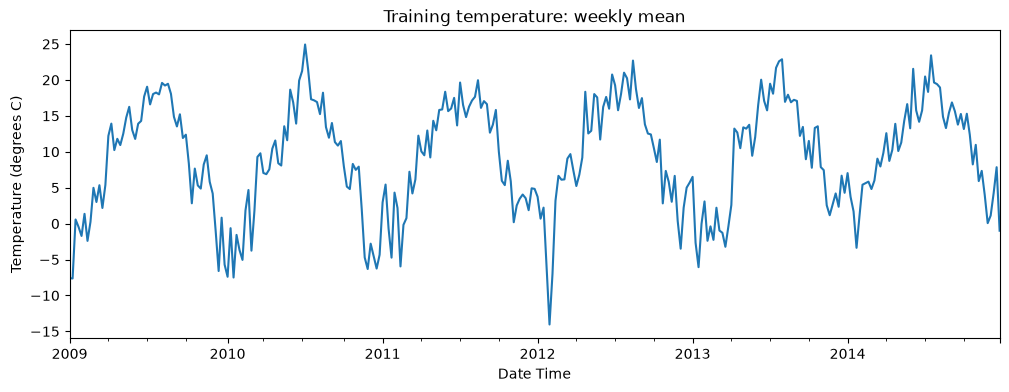

In [4]:
import matplotlib.pyplot as plt
parts['train'][TARGET].resample('7D').mean().plot(figsize=(12,4),title='Training temperature: weekly mean')
plt.ylabel('Temperature (degrees C)')
plt.show()

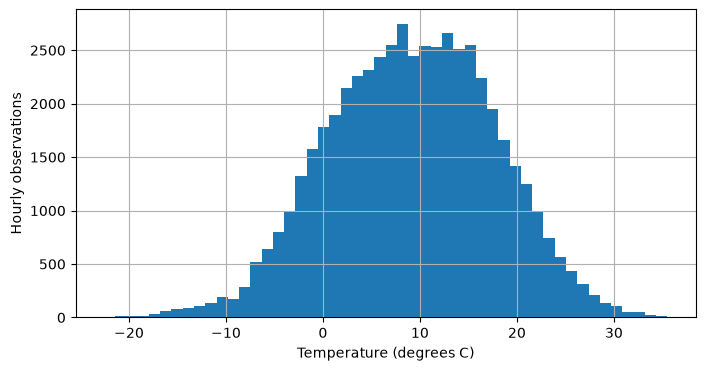

In [5]:
parts['train'][TARGET].hist(bins=50,figsize=(8,4))
plt.xlabel('Temperature (degrees C)')
plt.ylabel('Hourly observations')
plt.show()

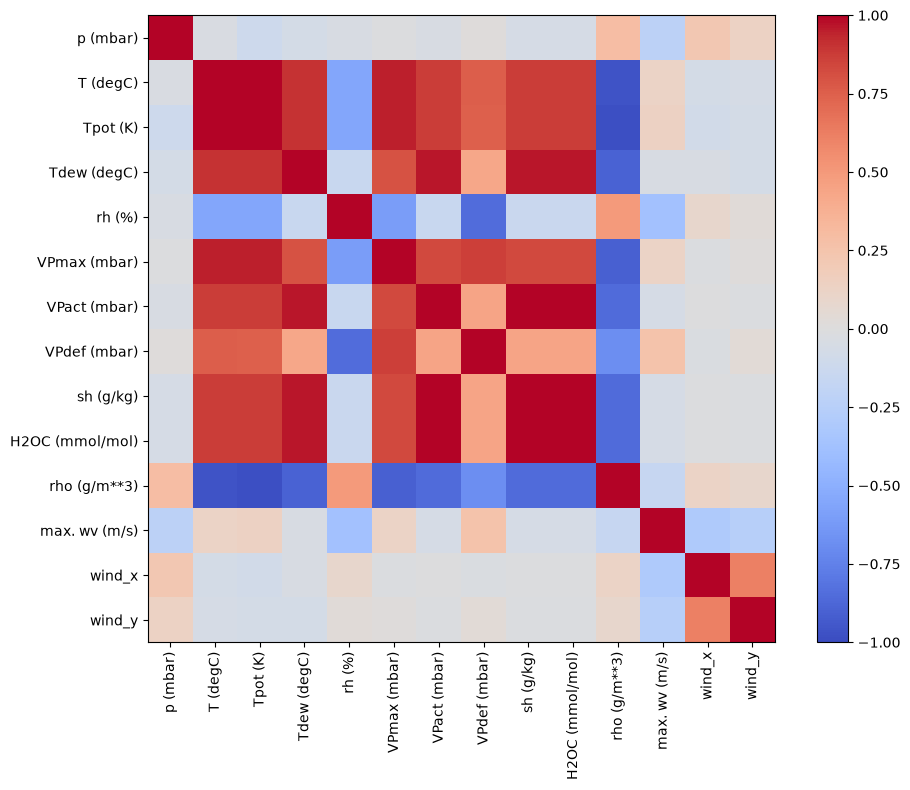

In [6]:
corr=parts['train'].corr()
fig,ax=plt.subplots(figsize=(10,8))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(corr)),corr.columns,rotation=90)
ax.set_yticks(range(len(corr)),corr.columns)
fig.colorbar(im,ax=ax)
plt.tight_layout()
plt.show()

## Interpretation
Inspect annual variation, extreme temperatures, correlated thermodynamic variables and invalid wind counts. Fit all statistics on training years only. Test-period plots are for final reporting after selection, not feature tuning.